# Pydantic

**이 노트북에서 할 일**

1. 클래스 `BaseModel`을 물려받은 주문 줄 모델을 만들고, 규칙에 맞지 않는 값에서 나는 검증 오류를 읽습니다.
2. 수량 범위 규칙 `Field(ge=1, le=10)`을 더하고, 수량 10과 11을 넣어 봅니다.
3. 수량 글자를 `int()`로 바꾸지 않고 넣었을 때 모델이 알리도록 `strict=True`를 더합니다.

**준비물** — API 키 불필요. 언어 모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

데이터 검사 라이브러리 Pydantic 2.13.5는 실습 폴더에서 `uv sync --locked`를 실행할 때 함께 설치됩니다.
이 절은 확장 경로(B)입니다. 1~9절과 같은 실습 폴더 `labs/part1/ch02-python`의 `.venv`를 커널로 고르고, 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

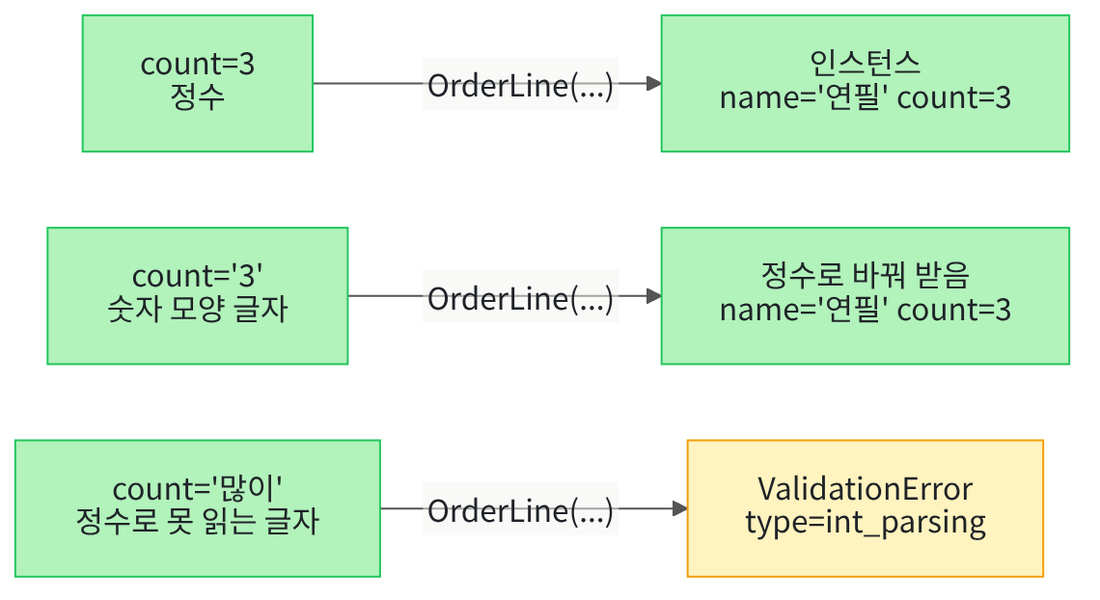

왼쪽의 입력이 오른쪽의 결과가 됩니다. 왼쪽 초록 상자는 우리가 넣은 값, 오른쪽 초록 상자는 만들어진 인스턴스, 노란 상자는 출력입니다.

세 입력 모두 같은 모델 OrderLine을 지납니다. 글자 '3'은 정수 3으로 바뀌어 들어가고, 글자 '많이'는 오류로 알려집니다.

## 1. 준비

데이터 검사 라이브러리 Pydantic은 실습 폴더의 pyproject.toml에 2.13.5 버전으로 적혀 있습니다.
준비 셀은 8절 pytest처럼 커널에서 패키지를 불러와 버전을 출력합니다.

오류 `ModuleNotFoundError`가 나오면, Ch 1 3절처럼 커널이 실습 폴더의 `.venv`인지 확인합니다.

In [1]:
# 실습 폴더 가상환경에 설치된 Pydantic을 불러와 버전을 확인합니다
import pydantic

# __version__은 패키지에 적어 둔 버전 글자입니다
print("pydantic 버전:", pydantic.__version__)

pydantic 버전: 2.13.5


**결과 읽기** — pydantic 버전은 `2.13.5`로, pyproject.toml에 적은 버전과 같습니다.
이 절은 파일을 만들지 않으므로 임시 폴더로 옮기지 않습니다.

## 2. 필드만 적은 모델 정의하기

7절에서 `unit_price: int`라고 적어도 글자 '39000'이 그대로 들어가 금액이 3900039000이 되었습니다. 타입힌트는 표시일 뿐 값을 검사하지 않았습니다.
라이브러리 Pydantic은 같은 모양의 표시를 읽고, 들어온 값을 실제로 검사합니다.

데이터 검증(data validation)은 들어온 값이 약속한 자료형과 범위에 맞는지 확인하는 일입니다.
이 절에서 모델(model)은 필드 이름과 자료형 규칙을 적은 클래스를 말합니다. 뒤 챕터에서 부르는 언어 모델과는 다른 뜻입니다.

클래스 이름 뒤 괄호에 다른 클래스를 적으면, 새 클래스가 그 클래스의 기능을 물려받습니다. 이것을 상속(inheritance)이라고 합니다.
인쇄소가 만든 빈 양식 용지에 칸 이름만 적어 우리 가게 주문서를 만드는 것과 비슷합니다.
아래 셀의 `class OrderLine(BaseModel):` 줄은 Pydantic의 클래스 `BaseModel`이 가진 검사 기능을 물려받습니다. 상속으로 클래스를 직접 설계하는 방법은 이 절에서 다루지 않습니다.

클래스 본문에 `이름: 자료형`만 적은 줄을 필드(field)라고 합니다. 7절 매개변수 타입힌트와 같은 모양입니다.
6절 OrderLine은 `__init__` 안에 `self.name = name`을 적었지만, 이번에는 필드 두 줄만 적습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [2]:
# 상품 이름과 수량, 두 필드를 적은 주문 줄 모델을 정의합니다
from pydantic import BaseModel


# 괄호 안 BaseModel의 검사 기능을 물려받고, 필드는 이름과 자료형만 적습니다
class OrderLine(BaseModel):
    name: str
    count: int

**결과 읽기** — 예상대로 출력이 없습니다. 모델 OrderLine에는 필드 name(글자)과 count(정수)가 있습니다.
메서드는 적지 않았습니다. 이 절의 모델은 필드만 적습니다.

## 3. 키워드 인자로 인스턴스 만들기

6절처럼 클래스 이름을 함수처럼 부르면 인스턴스가 만들어집니다. 이번에는 5절 키워드 인자로 필드 이름을 붙여 값을 넣습니다.
Pydantic 문서는 모델을 부를 때 필드 값을 키워드 인자로 넣어야 한다고 설명합니다.

만들어진 인스턴스는 6절처럼 점 뒤에 필드 이름을 적어 읽습니다.
실행 전에 예상합니다. 상품 이름은 연필, 수량은 3일 것입니다.

In [3]:
# 필드 이름을 키워드 인자로 적어 인스턴스를 만듭니다
pencil = OrderLine(name="연필", count=3)
print("인스턴스:", pencil)
# 6절처럼 점 뒤에 필드 이름을 적어 값을 읽습니다
print("상품 이름:", pencil.name)
print("수량:", pencil.count)

인스턴스: name='연필' count=3
상품 이름: 연필
수량: 3


**결과 읽기** — 인스턴스를 출력한 줄은 `인스턴스: name='연필' count=3`이고, 상품 이름은 `연필`, 수량은 `3`으로 예상과 같습니다.
클래스 BaseModel을 물려받은 인스턴스는 print로 필드 이름과 값을 함께 보여 줍니다.

## 4. 규칙에 맞지 않는 값 넣기 — 글자 '많이'

5절 bad_orders.txt의 첫 줄은 수량 자리에 글자 '많이'가 있었습니다. 그 글자를 `int()`로 바꾸자 `ValueError`가 났습니다.
이번에는 같은 글자를 정수 필드 count에 넣습니다.

값이 필드 규칙에 맞지 않으면 모델은 인스턴스를 만들지 않고 검증 오류 `ValidationError`를 냅니다. 이 오류 이름은 Pydantic이 정한 이름이라 pydantic에서 가져옵니다.
오류를 관찰하려고 5절처럼 그 오류 이름만 받는 `try`와 `except`로 감쌉니다.

실행 전에 예상합니다. 인스턴스 줄은 나오지 않고 오류 메시지가 나올 것입니다.

In [4]:
# 수량에 5절 bad_orders.txt의 글자 '많이'를 넣어 인스턴스를 만들어 봅니다
from pydantic import ValidationError

try:
    bad_line = OrderLine(name="연필", count="많이")
    print("인스턴스:", bad_line)
except ValidationError as error:
    print("오류 메시지:", error)

오류 메시지: 1 validation error for OrderLine
count
  Input should be a valid integer, unable to parse string as an integer [type=int_parsing, input_value='많이', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/int_parsing


**결과 읽기** — 인스턴스 줄은 나오지 않았고, 오류 메시지의 첫 줄은 `1 validation error for OrderLine`입니다. 모델 OrderLine에서 검증 오류가 1개 났다는 뜻입니다.
둘째 줄 `count`는 문제가 난 필드 이름입니다. 셋째 줄 영어 설명은 정수가 와야 하는데 글자를 정수로 읽을 수 없다는 뜻입니다.

셋째 줄 대괄호 안의 `type=int_parsing`은 오류 종류, `input_value='많이'`는 받은 값입니다. 마지막 줄은 이 오류 종류를 설명한 문서 주소입니다.

## 5. 숫자 모양 글자 넣기 — 글자 "3"

1절에서 `int()`로 글자 "2"를 정수 2로 바꿨습니다. 7절에서는 바꾸지 않은 글자 '39000'이 함수에 그대로 들어갔습니다.
이번에는 숫자 모양 글자 "3"을 정수 필드 count에 넣고, 인스턴스에 저장된 수량의 자료형을 봅니다.

실행 전에 예상해 봅니다. 7절처럼 글자가 그대로 저장될까요, 아니면 오류가 날까요?

In [5]:
# 수량에 숫자 모양 글자 "3"을 넣어 인스턴스를 만듭니다
text_line = OrderLine(name="연필", count="3")
print("수량:", text_line.count)
count_type = type(text_line.count)
print("수량의 자료형:", count_type)

수량: 3
수량의 자료형: <class 'int'>


**결과 읽기** — 오류 없이 수량 `3`이 저장되었고, 수량의 자료형은 `<class 'int'>`입니다.

라이브러리 Pydantic의 기본 모드는 정수로 바꿀 수 있는 글자를 정수로 바꿔 받습니다. 이것을 자동 변환(coercion)이라고 합니다.
문서는 이 기본 모드를 느슨한 모드(lax mode)라고 부릅니다. 4번의 글자 '많이'는 정수로 바꿀 수 없어서 오류가 났습니다.

## 6. 딕셔너리로 받고 딕셔너리로 꺼내기

주문 자료를 3절 딕셔너리 모양으로 받을 때도 있습니다. 메서드 `model_validate()`는 딕셔너리를 받아 같은 검사를 하고 인스턴스를 반환합니다.
이 메서드는 인스턴스가 아니라 클래스 이름 뒤에 점을 찍고 부릅니다.

거꾸로 메서드 `model_dump()`는 인스턴스의 필드를 딕셔너리로 반환합니다.
실행 전에 예상합니다. 꺼낸 딕셔너리는 처음 딕셔너리와 같을 것입니다.

In [6]:
# 딕셔너리로 인스턴스를 만들고, 인스턴스를 다시 딕셔너리로 꺼냅니다
order_data = {"name": "노트", "count": 2}
# model_validate()는 딕셔너리를 검사해 인스턴스를 반환합니다
note = OrderLine.model_validate(order_data)
print("인스턴스:", note)
# model_dump()는 인스턴스의 필드를 딕셔너리로 반환합니다
note_data = note.model_dump()
is_same = note_data == order_data
print("꺼낸 딕셔너리:", note_data)
print("처음 딕셔너리와 같은가:", is_same)

인스턴스: name='노트' count=2
꺼낸 딕셔너리: {'name': '노트', 'count': 2}
처음 딕셔너리와 같은가: True


**결과 읽기** — 인스턴스는 `name='노트' count=2`이고, 꺼낸 딕셔너리는 `{'name': '노트', 'count': 2}`입니다. 처음 딕셔너리와 같은가 줄은 `True`로 예상과 같습니다.
딕셔너리의 키 이름이 필드 이름과 같아서 그대로 들어가고 그대로 나왔습니다.

## 7. 수량 범위 규칙 더하기 — Field

가게에서 「한 줄에 수량은 1개 이상 10개 이하」로 정했다고 합니다. 자료형만으로는 이 규칙을 적을 수 없습니다.
함수 `Field()`는 필드에 붙일 규칙 묶음을 만듭니다. 인자 `ge=1`은 1 이상, `le=10`은 10 이하라는 규칙입니다.

필드 줄 `count: int = Field(ge=1, le=10)`은 7절 매개변수 `quantity: int = 1`과 모양이 같습니다. 다만 등호 뒤는 기본값이 아니라 규칙 묶음입니다.
9절처럼 같은 이름 OrderLine으로 다시 정의하므로, 앞의 정의는 덮어씁니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [7]:
# 수량은 1 이상 10 이하라는 범위 규칙을 더해 모델을 다시 정의합니다
from pydantic import Field


class OrderLine(BaseModel):
    name: str
    # ge=1은 1 이상, le=10은 10 이하라는 규칙입니다
    count: int = Field(ge=1, le=10)

**결과 읽기** — 예상대로 출력이 없습니다. 이제 이름 OrderLine에는 범위 규칙이 있는 모델이 들어 있습니다.

## 8. 경계 값 10 넣기

수량에 규칙의 끝 값 10을 넣어 봅니다. 규칙을 어기면 오류 정보를 출력하도록 except 블록도 미리 적어 둡니다.

검증 오류의 메서드 `errors()`는 문제 하나마다 딕셔너리 하나를 담은 목록을 반환합니다.
딕셔너리의 키 `loc`에는 문제가 난 필드 위치가, `type`에는 오류 종류가, `input`에는 받은 값이 들어 있습니다. 4번 메시지에서 읽은 내용을 키로 꺼내는 방법입니다.

실행 전에 예상합니다. 10은 「10 이하」에 맞으므로 인스턴스가 만들어질 것입니다.

In [8]:
# 수량 10을 넣어 범위 규칙을 확인합니다(규칙을 어기면 오류 정보를 출력합니다)
try:
    checked_line = OrderLine(name="연필", count=10)
    print("인스턴스:", checked_line)
except ValidationError as error:
    # errors()는 문제 하나마다 딕셔너리 하나를 담은 목록을 반환합니다
    problems = error.errors()
    print("문제 필드:", problems[0]["loc"])
    print("오류 종류:", problems[0]["type"])
    print("받은 값:", problems[0]["input"])

인스턴스: name='연필' count=10


**결과 읽기** — 출력은 `인스턴스: name='연필' count=10` 한 줄로 예상과 같습니다. 끝 값 10도 규칙 안에 들어갑니다.
except 블록의 줄은 실행되지 않았습니다.

## 9. 값 바꿔 보기 — 수량 11

8번 셀에서 수량 인자 하나만 10에서 11로 바꿉니다.

실행 전에 예상합니다. 인스턴스 줄은 나오지 않고, 문제 필드는 count일 것입니다. 오류 종류는 10 이하 규칙을 어겼다는 이름일 것입니다.

In [9]:
# 값 바꿔 보기: 수량 인자만 10에서 11로 바꿉니다
try:
    checked_line = OrderLine(name="연필", count=11)
    print("인스턴스:", checked_line)
except ValidationError as error:
    # errors()는 문제 하나마다 딕셔너리 하나를 담은 목록을 반환합니다
    problems = error.errors()
    print("문제 필드:", problems[0]["loc"])
    print("오류 종류:", problems[0]["type"])
    print("받은 값:", problems[0]["input"])

문제 필드: ('count',)
오류 종류: less_than_equal
받은 값: 11


**결과 읽기** — 문제 필드는 `('count',)`, 오류 종류는 `less_than_equal`, 받은 값은 `11`입니다.

오류 종류 less_than_equal은 「이하」 규칙을 어겼다는 뜻입니다. 필드 위치 ('count',)는 값이 하나인 튜플로, 9절의 (39000,)과 같은 모양입니다.
자료형은 정수로 맞았지만 범위 규칙에서 걸렸습니다. 자료형 검사와 범위 검사는 따로 일어납니다.

## 10. Before — int() 줄을 빠뜨려도 모델이 알리지 않음

5절에서는 줄 "연필,3"을 `split(",")`로 나눈 뒤 수량 글자를 `int()`로 바꿨습니다. 7절과 8절에서는 이 `int()` 줄을 빠뜨린 결함을 보았습니다.
이 프로그램은 수량을 `int()`로 바꾼 뒤 모델에 넣기로 약속했다고 합니다. 줄을 빠뜨리면 모델이 입구에서 알려 주면 좋겠습니다.

아래 셀은 `int()` 줄을 빠뜨린 채 수량 글자를 범위 규칙이 있는 모델에 넣습니다. 오류로 알리면 표시 was_reported를 True로 바꿉니다.

실행 전에 예상해 봅니다. 5번에서 글자 "3"은 정수로 바뀌었습니다. 모델이 빠뜨린 줄을 알려 줄까요?

In [10]:
# 줄 "연필,3"을 나누고, 수량 글자를 int()로 바꾸지 않은 채 모델에 넣습니다
line = "연필,3"
name, count_text = line.split(",")
was_reported = False
try:
    order_line = OrderLine(name=name, count=count_text)
    print("인스턴스:", order_line)
except ValidationError as error:
    problems = error.errors()
    print("오류 종류:", problems[0]["type"])
    # 모델이 오류로 알렸다는 표시를 남깁니다
    was_reported = True
print("넣은 수량의 자료형:", type(count_text))
print("모델이 알렸나요?", was_reported)

인스턴스: name='연필' count=3
넣은 수량의 자료형: <class 'str'>
모델이 알렸나요? False


**결과 읽기** — 출력은 `인스턴스: name='연필' count=3`, `넣은 수량의 자료형: <class 'str'>`, `모델이 알렸나요? False` 세 줄입니다.

모델은 글자 '3'을 정수 3으로 바꿔 받고, 오류를 내지 않았습니다. 그런데 이름 count_text에는 여전히 글자가 들어 있습니다.
7절처럼 이 글자를 다른 계산에 그대로 쓰면 결함이 생깁니다. 자동 변환이 빠뜨린 `int()` 줄을 가렸습니다.

## 11. After — 수량 필드에 strict=True 더하기

엄격 모드(strict mode)는 값을 바꾸지 않고, 들어온 값의 자료형이 맞는지만 확인하는 방법입니다.
함수 `Field()`의 괄호에 `strict=True`를 더하면 그 필드 하나에 엄격 모드를 씁니다.

Before 모델과 달라진 곳은 인자 `strict=True` 하나입니다. 범위 규칙 `ge=1, le=10`은 그대로 둡니다.
같은 이름 OrderLine으로 다시 정의합니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [11]:
# 수량 필드에 strict=True를 더해 모델을 다시 정의합니다(범위 규칙은 그대로)
class OrderLine(BaseModel):
    name: str
    # strict=True는 글자를 정수로 바꾸지 않고, 정수가 아니면 오류를 냅니다
    count: int = Field(strict=True, ge=1, le=10)

**결과 읽기** — 예상대로 출력이 없습니다. 필드 name과 범위 규칙은 Before 모델과 같습니다.

Before 셀과 같은 줄, 같은 코드로 다시 실행합니다. 셀 끝에 모델이 알렸는지 확인하는 `assert` 줄을 더합니다.

실행 전에 예상합니다. 이번에는 인스턴스 줄 대신 오류 종류가 나오고, 모델이 알렸나요? 줄은 True일 것입니다. 오류 종류는 4번의 int_parsing과 같을까요?

In [12]:
# 줄 "연필,3"을 나누고, 수량 글자를 int()로 바꾸지 않은 채 모델에 넣습니다
line = "연필,3"
name, count_text = line.split(",")
was_reported = False
try:
    order_line = OrderLine(name=name, count=count_text)
    print("인스턴스:", order_line)
except ValidationError as error:
    problems = error.errors()
    print("오류 종류:", problems[0]["type"])
    # 모델이 오류로 알렸다는 표시를 남깁니다
    was_reported = True
print("넣은 수량의 자료형:", type(count_text))
print("모델이 알렸나요?", was_reported)
# 모델이 오류로 알리지 않았으면 이 줄에서 멈춥니다
assert was_reported

오류 종류: int_type
넣은 수량의 자료형: <class 'str'>
모델이 알렸나요? True


**결과 읽기** — 출력은 `오류 종류: int_type`, `넣은 수량의 자료형: <class 'str'>`, `모델이 알렸나요? True` 세 줄입니다. 검사 줄 `assert`에서도 멈추지 않았습니다.

오류 종류 int_type은 정수 자료형이 아니라는 뜻입니다. 4번의 int_parsing은 글자를 정수로 읽을 수 없다는 뜻이었습니다.
엄격한 필드는 글자 '3'을 읽어 보지 않고, 자료형이 글자라서 바로 오류를 냈습니다.

빠뜨린 `int()` 줄을 더해, 수량을 정수로 바꾼 뒤 같은 엄격한 모델에 넣습니다.

실행 전에 예상합니다. 이번에는 인스턴스가 만들어지고, 넣은 수량의 자료형은 int일 것입니다.

In [13]:
# 빠뜨린 int() 줄을 더해, 수량을 정수로 바꾼 뒤 엄격한 모델에 넣습니다
count = int(count_text)
fixed_line = OrderLine(name=name, count=count)
print("인스턴스:", fixed_line)
print("넣은 수량의 자료형:", type(count))
# 엄격한 모델도 범위 안의 정수는 받습니다
assert fixed_line.count == 3

인스턴스: name='연필' count=3
넣은 수량의 자료형: <class 'int'>


**결과 읽기** — 출력은 `인스턴스: name='연필' count=3`과 `넣은 수량의 자료형: <class 'int'>`입니다. 검사 줄 `assert`에서도 멈추지 않았습니다.

엄격한 모델은 `int()` 줄을 빠뜨린 코드는 알리고, 줄을 더한 코드는 받았습니다.
이번에 엄격한 모델에 넣은 값은 글자 '3'과 정수 3 두 가지입니다. 범위를 벗어난 정수를 엄격한 모델에 넣는 장면은 실행하지 않았습니다.

### 원리 더 알아보기 — 모델이 적어 둔 규칙표

메서드 `model_json_schema()`는 모델의 필드 규칙을 JSON 스키마(JSON Schema)라는 약속된 모양의 딕셔너리로 반환합니다.
Ch 19에서 도구의 입력 규칙을 볼 때 같은 메서드를 다시 만납니다. 지금은 출력만 읽습니다.

In [14]:
# 원리 더 알아보기: 모델 OrderLine의 필드 규칙을 딕셔너리로 꺼내 봅니다
rule_table = OrderLine.model_json_schema()
print("반드시 넣을 필드:", rule_table["required"])
count_rule = rule_table["properties"]["count"]
print("수량 필드의 규칙:", count_rule)

반드시 넣을 필드: ['name', 'count']
수량 필드의 규칙: {'maximum': 10, 'minimum': 1, 'title': 'Count', 'type': 'integer'}


**결과 읽기** — 반드시 넣을 필드는 `['name', 'count']`입니다. 수량 필드의 규칙은 `{'maximum': 10, 'minimum': 1, 'title': 'Count', 'type': 'integer'}`입니다.
규칙표에서 인자 ge=1은 minimum 1로, 인자 le=10은 maximum 10으로 적혔습니다. 엄격 모드를 뜻하는 항목은 이 규칙표에 나오지 않았습니다.

## 정리

- 클래스 `BaseModel`을 물려받은 모델은 필드 두 줄로 값을 검사합니다. 글자 '많이'는 `int_parsing` 오류가 났고, 글자 "3"은 정수 3으로 바뀌었습니다.
- 범위 규칙 `Field(ge=1, le=10)`은 수량 10을 받고, 11은 `less_than_equal` 오류로 알렸습니다.
- `int()` 줄을 빠뜨린 수량 글자를 기본 모드는 받아 False가 나왔습니다. 인자 `strict=True`를 더하자 `int_type` 오류로 알려 True가 되었습니다.

확장 경로(B)는 11절 패키징과 테스트 격리로, 기본 경로(A)는 12절 async와 await로 이어집니다.